# Proyecto Final: Limpieza de Voz mediante Filtros FIR e IIR
**Instrucciones de reproducción:**
1. Subir los archivos `Audio_A.wav` y `Audio_B.wav` al directorio raíz del entorno de Colab.
2. Ejecutar las celdas en orden secuencial (`Entorno de ejecución > Ejecutar todas`).
3. Al finalizar, se generarán automáticamente los cuatro archivos solicitados: `A_FIR.wav`, `A_IIR.wav`, `B_FIR.wav` y `B_IIR.wav`.

---
## 0. Configuración del entorno e importación de librerías

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

# Configuración visual global para que las gráficas se vean nítidas en el reporte
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 10

## 1. Funciones auxiliares de análisis espectral, diseño y evaluación
Definición de las rutinas reutilizables para:
* Carga y normalización de señales WAV a $16\text{ kHz}$.
* Cálculo de FFT segmentada con ventana Hann (espectros individuales y promedio).
* Inspección de filtros digitales: $h[n]$, diagrama de polos/ceros en el Plano Z, respuesta en magnitud y fase.
* Filtrado, comparación de Densidad Espectral de Potencia (PSD) y cálculo de atenuación por bandas.

In [ ]:

def cargar_audio(ruta_wav):
    """Carga un WAV, lo convierte a mono si es necesario y lo normaliza a [-1, 1]."""
    fs, data = wavfile.read(ruta_wav)
    if data.ndim > 1:
        data = data.mean(axis=1)
    data = data.astype(np.float64)
    max_val = np.max(np.abs(data))
    if max_val > 0:
        data = data / max_val
    return fs, data

def guardar_y_reproducir(ruta_salida, fs, senal, etiqueta="Audio"):
    """Normaliza ligeramente para evitar clipping, guarda en int16 y muestra reproductor."""
    max_val = np.max(np.abs(senal))
    senal_norm = senal / max_val if max_val > 0 else senal
    wavfile.write(ruta_salida, fs, np.int16(senal_norm * 32767))
    print(f"▶️ {etiqueta} (guardado como '{ruta_salida}'):")
    display(Audio(senal_norm, rate=fs))



def analizar_espectro(senal, fs, n_muestras=1024, solapamiento=0.5, f_zoom=1000,
                      titulo="Señal", max_seg_graf=25, usar_db=False):
    """
    Grafica la señal en el tiempo, los espectros segmentados con ventana Hann,
    el espectro promedio completo (0 a Nyquist) y una ampliación en bajas frecuencias.
    """
    tiempo = np.arange(len(senal)) / fs
    nyquist = fs / 2.0
    paso = int(n_muestras * (1 - solapamiento))
    ventana = signal.windows.hann(n_muestras, sym=False)
    factor_escala = 1.0 / np.sum(ventana)

    espectros = []
    for inicio in range(0, len(senal) - n_muestras + 1, paso):
        seg = senal[inicio : inicio + n_muestras] * ventana
        mag = np.abs(np.fft.rfft(seg)) * factor_escala
        mag[1:-1] *= 2
        espectros.append(mag)

    espectros = np.array(espectros)
    espectro_prom = np.mean(espectros, axis=0)
    freqs = np.fft.rfftfreq(n_muestras, d=1.0/fs)

    # Conversión opcional a dB para observar mejor el piso de ruido
    eps = 1e-12
    esp_graf = 20 * np.log10(espectros + eps) if usar_db else espectros
    prom_graf = 20 * np.log10(espectro_prom + eps) if usar_db else espectro_prom
    ylabel_esp = "Magnitud [dB]" if usar_db else "Magnitud lineal"

    fig, axs = plt.subplots(3, 1, figsize=(10, 9))
    plt.subplots_adjust(hspace=0.42)

    # Tiempo
    axs[0].plot(tiempo, senal, color="steelblue", linewidth=0.7)
    axs[0].set_title(f"{titulo} — Dominio del tiempo (fs = {fs} Hz)")
    axs[0].set_xlabel("Tiempo [s]")
    axs[0].set_ylabel("Amplitud")

    indices = np.linspace(0, len(espectros) - 1, min(max_seg_graf, len(espectros)), dtype=int)

    # Espectro completo
    for idx in indices:
        axs[1].plot(freqs, esp_graf[idx], color="gray", alpha=0.25, linewidth=0.8)
    axs[1].plot(freqs, prom_graf, color="crimson", linewidth=1.6, label="Espectro promedio")
    axs[1].set_title(f"Espectro completo (0 a {nyquist:.0f} Hz) | N = {n_muestras} (Δf = {fs/n_muestras:.2f} Hz)")
    axs[1].set_xlabel("Frecuencia [Hz]")
    axs[1].set_ylabel(ylabel_esp)
    axs[1].set_xlim(0, nyquist)
    axs[1].legend()

    # Zoom bajas frecuencias
    for idx in indices:
        axs[2].plot(freqs, esp_graf[idx], color="gray", alpha=0.25, linewidth=0.8)
    axs[2].plot(freqs, prom_graf, color="darkgreen", linewidth=1.6, label="Espectro promedio")
    axs[2].set_title(f"Ampliación bajas frecuencias (0 a {f_zoom} Hz)")
    axs[2].set_xlabel("Frecuencia [Hz]")
    axs[2].set_ylabel(ylabel_esp)
    axs[2].set_xlim(0, f_zoom)
    axs[2].legend()

    plt.show()
    return freqs, espectro_prom

# INSPECCIÓN DE FILTRO: h[n], H(z), PLANO Z Y RESPUESTA EN FRECUENCIA
def inspeccionar_filtro(b, a, fs, titulo="Filtro Digital", f_zoom_resp=None):
    """
    Grafica h[n], el diagrama de polos y ceros en el Plano Z, y la respuesta en
    frecuencia (magnitud en dB y fase desenvuelta). Imprime ecuación en diferencias.
    """
    es_fir = (len(a) == 1 and a[0] == 1.0)
    orden = max(len(b), len(a)) - 1
    ceros, polos, _ = signal.tf2zpk(b, a)

    # Respuesta al impulso
    n_imp = max(len(b), 60) if es_fir else 100
    impulso = np.zeros(n_imp)
    impulso[0] = 1.0
    h_n = signal.lfilter(b, a, impulso)

    # Respuesta en frecuencia
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    mag_db = 20 * np.log10(np.abs(H) + 1e-12)
    fase = np.unwrap(np.angle(H))

    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.28)

    # 1. Respuesta al impulso h[n]
    ax_imp = fig.add_subplot(gs[0, 0])
    ax_imp.stem(np.arange(len(h_n)), h_n, basefmt=" ")
    ax_imp.set_title(f"{titulo} — Respuesta al impulso h[n] (Orden = {orden})")
    ax_imp.set_xlabel("Muestra n")
    ax_imp.set_ylabel("Amplitud")

    # 2. Plano Z (Polos y Ceros)
    ax_z = fig.add_subplot(gs[0, 1])
    theta = np.linspace(0, 2*np.pi, 300)
    ax_z.plot(np.cos(theta), np.sin(theta), "k--", alpha=0.5, label="Círculo unitario")
    ax_z.scatter(np.real(ceros), np.imag(ceros), marker="o", facecolors="none",
                 edgecolors="blue", s=50, label=f"Ceros ({len(ceros)})")
    if len(polos) > 0:
        ax_z.scatter(np.real(polos), np.imag(polos), marker="x", color="red",
                     s=60, label=f"Polos ({len(polos)})")
    ax_z.axhline(0, color="gray", linewidth=0.5)
    ax_z.axvline(0, color="gray", linewidth=0.5)
    ax_z.set_aspect("equal")
    ax_z.set_xlim(-1.3, 1.3)
    ax_z.set_ylim(-1.3, 1.3)
    ax_z.set_title("Plano Z (Polos y Ceros)")
    ax_z.set_xlabel("Parte Real")
    ax_z.set_ylabel("Parte Imaginaria")
    ax_z.legend(loc="upper right", fontsize=8)

    # 3. Magnitud en frecuencia
    ax_mag = fig.add_subplot(gs[1, 0])
    ax_mag.plot(w, mag_db, color="navy")
    ax_mag.set_title("Respuesta en Magnitud |H(e^jω)|")
    ax_mag.set_xlabel("Frecuencia [Hz]")
    ax_mag.set_ylabel("Ganancia [dB]")
    ax_mag.set_ylim(-90, 5)
    if f_zoom_resp:
        ax_mag.set_xlim(0, f_zoom_resp)

    # 4. Fase en frecuencia
    ax_fase = fig.add_subplot(gs[1, 1])
    ax_fase.plot(w, fase, color="darkorange")
    ax_fase.set_title("Respuesta en Fase ∠H(e^jω) (Desenvuelta)")
    ax_fase.set_xlabel("Frecuencia [Hz]")
    ax_fase.set_ylabel("Fase [rad]")
    if f_zoom_resp:
        ax_fase.set_xlim(0, f_zoom_resp)

    plt.show()

    # Resumen textual de H(z) y Ecuación en Diferencias
    print(f"--- Resumen Matemático: {titulo} ---")
    if es_fir:
        retardo_ms = ((orden / 2.0) / fs) * 1000
        print(f"Tipo: FIR de fase lineal | Orden M = {orden} ({len(b)} coeficientes) | Retardo de grupo = {orden/2:.1f} muestras ({retardo_ms:.2f} ms)")
        print(f"Primeros 5 coeficientes b[0..4]: {np.round(b[:5], 6)}")
        print("Ecuación en diferencias: y[n] = Σ_{k=0}^{M} b[k] · x[n - k]")
        print("Función de transferencia:  H(z) = Σ_{k=0}^{M} b[k] · z^{-k}")
    else:
        print(f"Tipo: IIR | Orden = {orden} | Máximo radio de polos = {np.max(np.abs(polos)):.5f} (< 1 => Estable)")
        print(f"Coeficientes numerador b:   {np.round(b, 6)}")
        print(f"Coeficientes denominador a: {np.round(a, 6)}")
        print("Ecuación en diferencias: y[n] = Σ b[k]·x[n-k] - Σ_{m=1}^{N} a[m]·y[n-m]")


# 4. APLICACIÓN DEL FILTRO, COMPARATIVA ANTES/DESPUÉS Y MÉTRICA CUANTITATIVA
def aplicar_y_comparar(senal_orig, b, a, fs, banda_ruido, banda_voz=(300, 3400),
                       fase_cero=False, n_fft=1024, f_zoom=None, titulo="Comparación"):
    """
    Filtra la señal (causal con lfilter o fase cero con filtfilt), grafica el espectro
    antes vs. después y calcula la atenuación de potencia en banda de ruido vs. voz.
    """
    if fase_cero:
        filtrada = signal.filtfilt(b, a, senal_orig)
        modo = "Fase cero (filtfilt - no causal)"
    else:
        filtrada = signal.lfilter(b, a, senal_orig)
        modo = "Causal (lfilter)"

    # Cálculo de espectros promedio (Welch con ventana Hann para suavidad)
    freqs, psd_orig = signal.welch(senal_orig, fs=fs, window="hann", nperseg=n_fft)
    _, psd_filt = signal.welch(filtrada, fs=fs, window="hann", nperseg=n_fft)

    # Potencia integrada por bandas
    def potencia_banda(f, psd, f_min, f_max):
        idx = np.logical_and(f >= f_min, f <= f_max)
        df = f[1] - f[0]
        return np.sum(psd[idx]) * df

    p_ruido_antes = potencia_banda(freqs, psd_orig, *banda_ruido)
    p_ruido_desp  = potencia_banda(freqs, psd_filt, *banda_ruido)
    aten_ruido_db = 10 * np.log10((p_ruido_desp + 1e-18) / (p_ruido_antes + 1e-18))

    p_voz_antes = potencia_banda(freqs, psd_orig, *banda_voz)
    p_voz_desp  = potencia_banda(freqs, psd_filt, *banda_voz)
    var_voz_db  = 10 * np.log10((p_voz_desp + 1e-18) / (p_voz_antes + 1e-18))

    # Gráfica comparativa antes vs después
    plt.figure(figsize=(10, 4))
    plt.semilogy(freqs, psd_orig, label="Señal contaminada", color="crimson", alpha=0.8)
    plt.semilogy(freqs, psd_filt, label=f"Señal filtrada ({modo})", color="teal", linewidth=1.5)
    plt.axvspan(banda_ruido[0], banda_ruido[1], color="orange", alpha=0.15, label=f"Banda ruido eval. {banda_ruido} Hz")
    plt.title(f"{titulo} — Densidad Espectral de Potencia (Antes vs. Después)")
    plt.xlabel("Frecuencia [Hz]")
    plt.ylabel("PSD [V²/Hz]")
    if f_zoom:
        plt.xlim(0, f_zoom)
    plt.legend()
    plt.show()

    print(f"📊 Métricas cuantitativas ({modo}):")
    print(f"   • Cambio de potencia en banda de ruido {banda_ruido} Hz: {aten_ruido_db:+.2f} dB")
    print(f"   • Cambio de potencia en banda de voz   {banda_voz} Hz:   {var_voz_db:+.2f} dB")

    return filtrada, {"aten_ruido_db": aten_ruido_db, "var_voz_db": var_voz_db, "modo": modo}

## 2. Diagnóstico inicial y análisis FFT por ventanas
### 2.1 Carga y reproducción de los audios contaminados
Inspección temporal y auditiva de las señales de entrada (`Audio_A.wav` con interferencia tonal de $60\text{ Hz}$ y `Audio_B.wav` con ruido de banda ancha).

In [ ]:

RUTA_AUDIO_A = "PDS_voz_60Hz_4s.wav"  # Voz + tono senoidal de 60 Hz
RUTA_AUDIO_B = "PDS_voz_fuente_simulada_4s.wav"  # Voz + ruido de agua (banda ancha)

fs_a, audio_a = cargar_audio(RUTA_AUDIO_A)
fs_b, audio_b = cargar_audio(RUTA_AUDIO_B)

print(f"Audio A cargado: fs = {fs_a} Hz | Duración = {len(audio_a)/fs_a:.2f} s | Muestras = {len(audio_a)}")
display(Audio(audio_a, rate=fs_a))

print(f"\nAudio B cargado: fs = {fs_b} Hz | Duración = {len(audio_b)/fs_b:.2f} s | Muestras = {len(audio_b)}")
display(Audio(audio_b, rate=fs_b))

Audio A cargado: fs = 16000 Hz | Duración = 4.00 s | Muestras = 64000



Audio B cargado: fs = 16000 Hz | Duración = 4.00 s | Muestras = 64000


### 2.2 Diagnóstico espectral del Audio A (Interferencia tonal de 60 Hz)
Comparación entre una ventana Hann corta ($N = 512$, $\Delta f = 31.25\text{ Hz}$) y una larga ($N = 2048$, $\Delta f = 7.81\text{ Hz}$) para aislar el pico en $60\text{ Hz}$ y ubicar el inicio de la banda vocal.

--- AUDIO A: Ventana corta (N = 512, mayor resolución temporal) ---


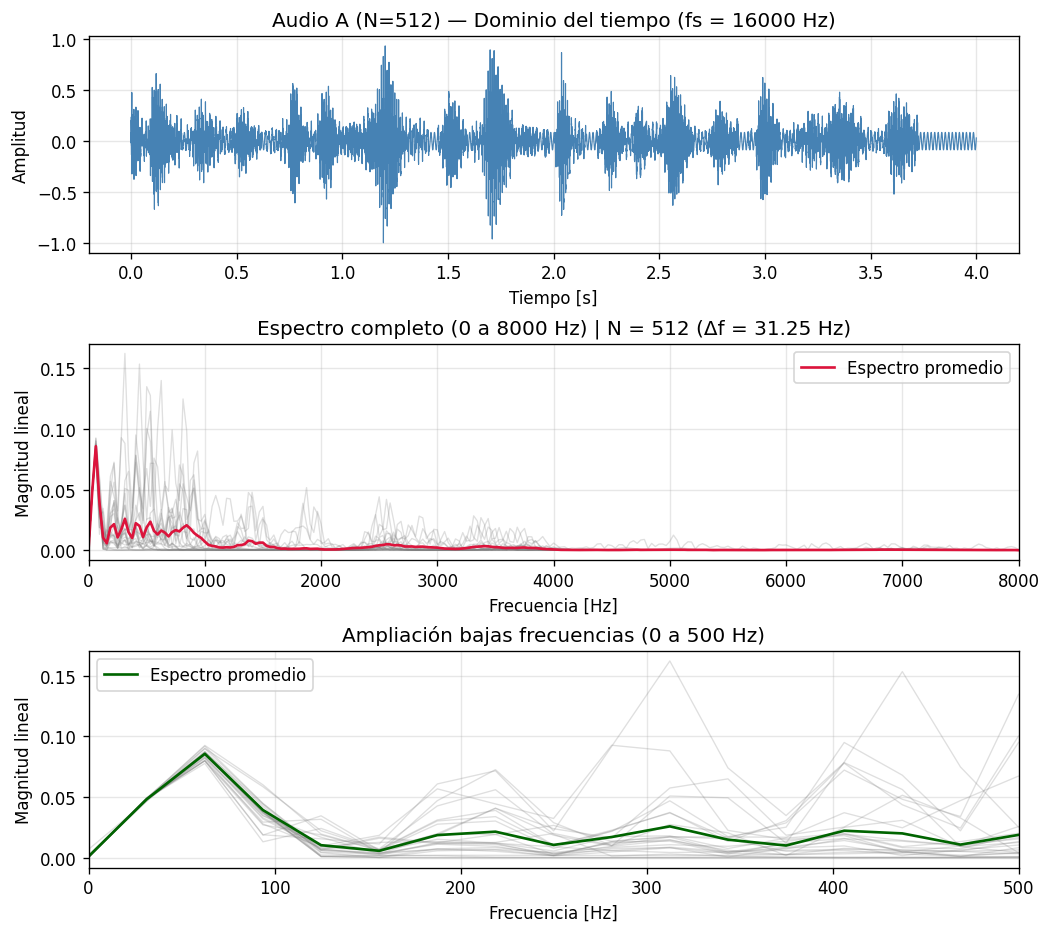


--- AUDIO A: Ventana larga (N = 2048, mayor resolución espectral) ---


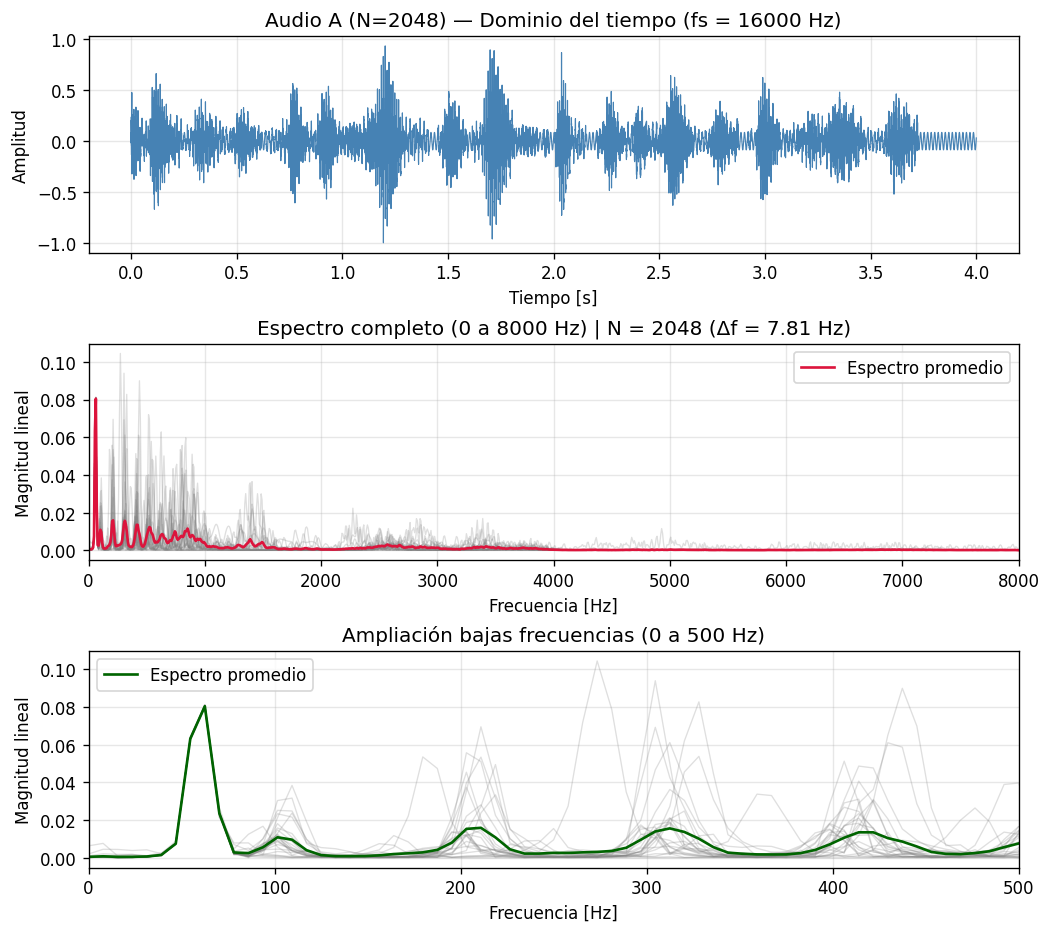

(array([0.0000000e+00, 7.8125000e+00, 1.5625000e+01, ..., 7.9843750e+03,
        7.9921875e+03, 8.0000000e+03], shape=(1025,)),
 array([5.21799412e-04, 8.02730449e-04, 5.07561582e-04, ...,
        1.23629814e-04, 9.52154930e-05, 4.53423206e-05], shape=(1025,)))

In [ ]:
print("--- AUDIO A: Ventana corta (N = 512, mayor resolución temporal) ---")
analizar_espectro(
    senal=audio_a,
    fs=fs_a,
    n_muestras=512,
    solapamiento=0.5,
    f_zoom=500,
    titulo="Audio A (N=512)",
    usar_db=False
)

print("\n--- AUDIO A: Ventana larga (N = 2048, mayor resolución espectral) ---")
analizar_espectro(
    senal=audio_a,
    fs=fs_a,
    n_muestras=2048,
    solapamiento=0.5,
    f_zoom=500,
    titulo="Audio A (N=2048)",
    usar_db=False
)

### 2.3 Diagnóstico espectral del Audio B (Ruido de agua / banda ancha)
Análisis en escala logarítmica (dB) con dos longitudes de ventana ($N = 256$ y $N = 1024$) para identificar la región de predominio de la voz y el solapamiento con el piso de ruido.

--- AUDIO B: Ventana corta (N = 256) en escala dB ---


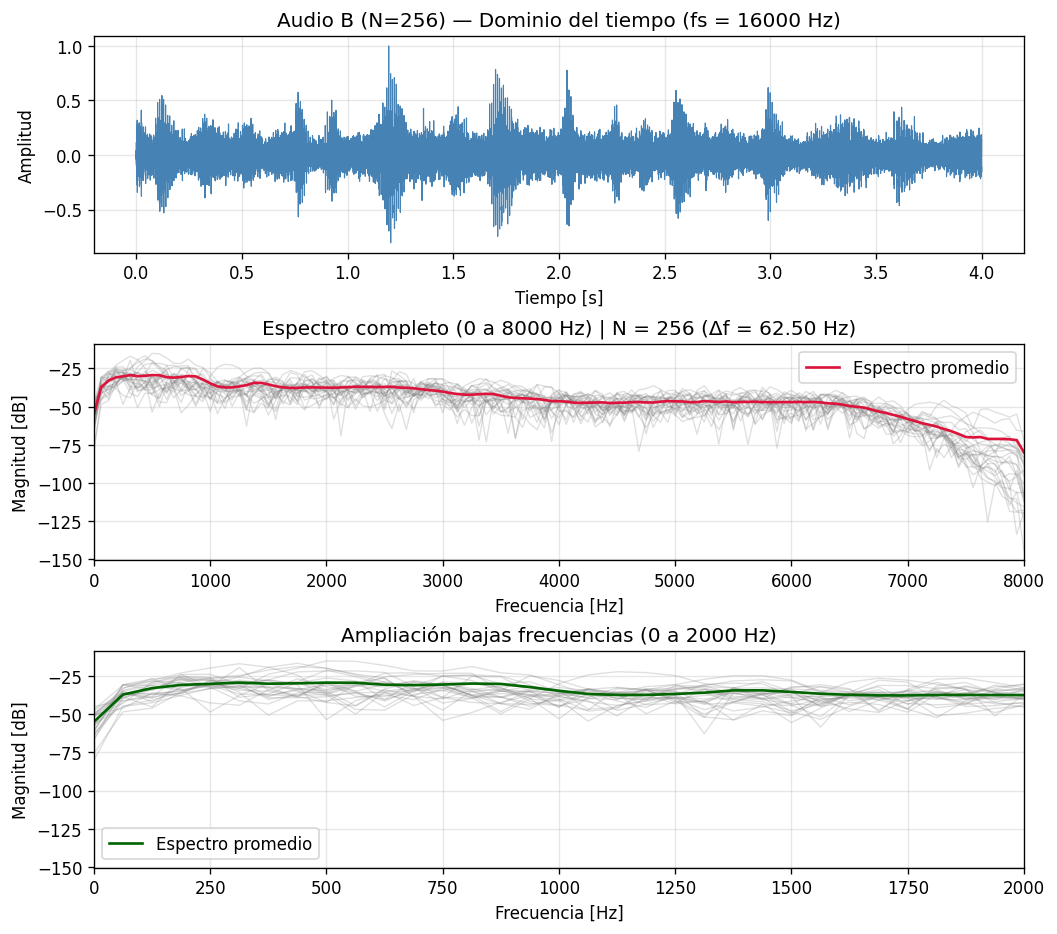


--- AUDIO B: Ventana media-larga (N = 1024) en escala dB ---


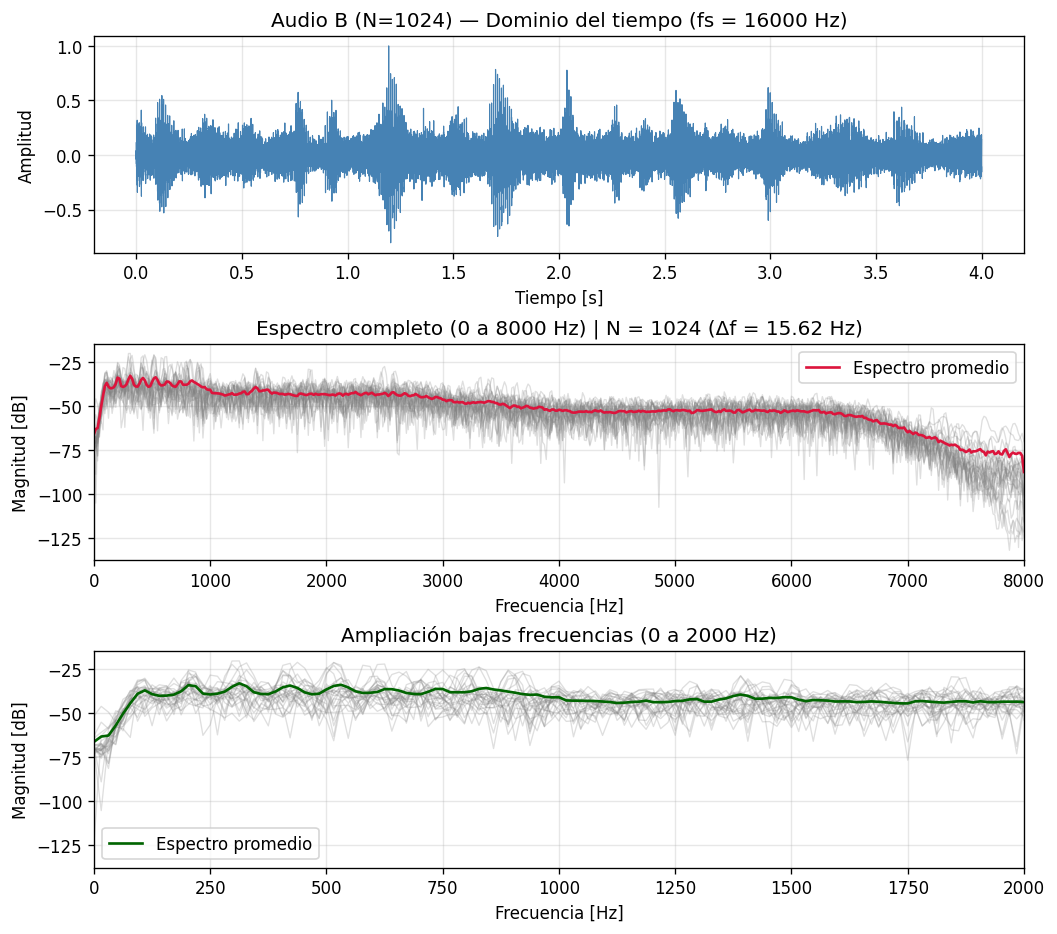

In [ ]:

print("--- AUDIO B: Ventana corta (N = 256) en escala dB ---")
analizar_espectro(
    senal=audio_b,
    fs=fs_b,
    n_muestras=256,
    solapamiento=0.5,
    f_zoom=2000,
    titulo="Audio B (N=256)",
    usar_db=True
)

print("\n--- AUDIO B: Ventana media-larga (N = 1024) en escala dB ---")
analizar_espectro(
    senal=audio_b,
    fs=fs_b,
    n_muestras=1024,
    solapamiento=0.5,
    f_zoom=2000,
    titulo="Audio B (N=1024)",
    usar_db=True
);

## 3. Diseño de filtros FIR por método de ventanas y análisis en el Plano Z
### 3.1 Filtro FIR rechaza-banda para Audio A (60 Hz)
Diseño a partir de una respuesta ideal truncada con ventana Hann, visualización de $h[n]$, ceros en el Plano Z, respuesta en frecuencia y exportación de `A_FIR.wav`.

/usr/local/lib/python3.13/dist-packages/scipy/signal/_filter_design.py:1230: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


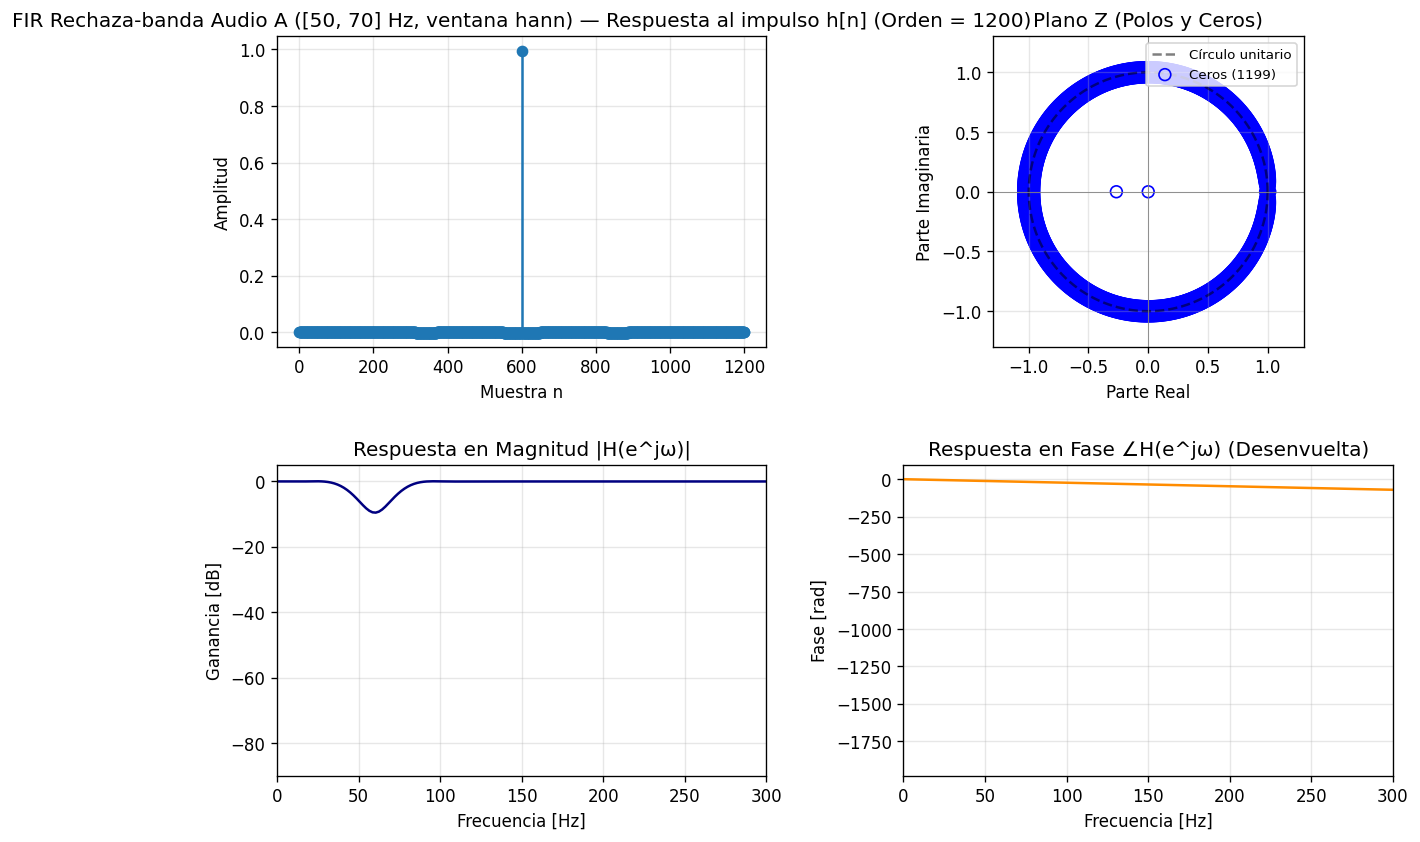

--- Resumen Matemático: FIR Rechaza-banda Audio A ([50, 70] Hz, ventana hann) ---
Tipo: FIR de fase lineal | Orden M = 1200 (1201 coeficientes) | Retardo de grupo = 600.0 muestras (37.50 ms)
Primeros 5 coeficientes b[0..4]: [-0. -0. -0. -0. -0.]
Ecuación en diferencias: y[n] = Σ_{k=0}^{M} b[k] · x[n - k]
Función de transferencia:  H(z) = Σ_{k=0}^{M} b[k] · z^{-k}


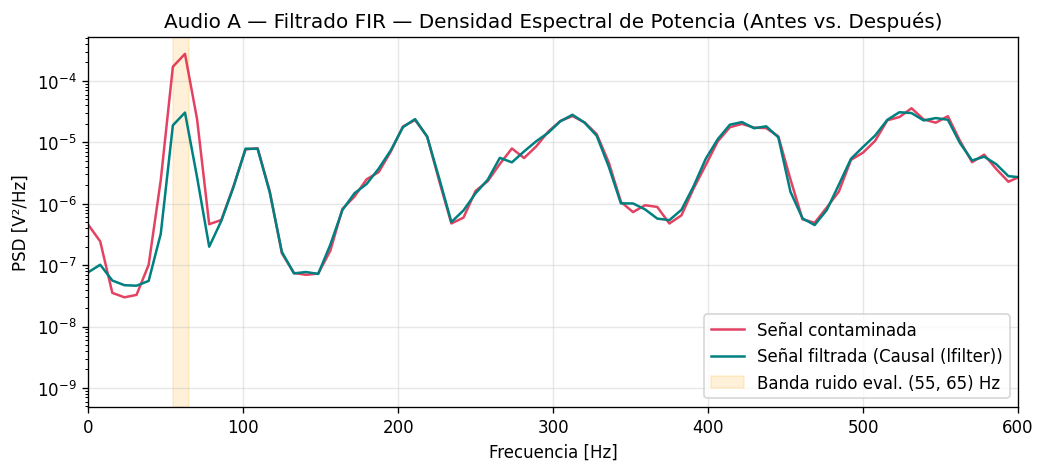

📊 Métricas cuantitativas (Causal (lfilter)):
   • Cambio de potencia en banda de ruido (55, 65) Hz: -9.56 dB
   • Cambio de potencia en banda de voz   (120, 3500) Hz:   -0.01 dB
▶️ Audio A filtrado (FIR) (guardado como 'A_FIR.wav'):


In [ ]:

ORDEN_FIR_A = 1200
BANDA_RECHAZO_A = [50, 70]
VENTANA_FIR_A = "hann"
FASE_CERO_A = False

# Diseño del filtro FIR por método de ventanas
b_fir_a = signal.firwin(
    numtaps=ORDEN_FIR_A + 1,
    cutoff=BANDA_RECHAZO_A,
    pass_zero=True,
    window=VENTANA_FIR_A,
    fs=fs_a
)
a_fir_a = np.array([1.0])

# 1. Inspección matemática: h[n], Plano Z y respuesta en frecuencia (zoom 0 a 300 Hz)
inspeccionar_filtro(
    b=b_fir_a,
    a=a_fir_a,
    fs=fs_a,
    titulo=f"FIR Rechaza-banda Audio A ({BANDA_RECHAZO_A} Hz, ventana {VENTANA_FIR_A})",
    f_zoom_resp=300
)

# 2. Aplicación al audio, comparación espectral y métricas cuantitativas
audio_a_fir, metricas_a_fir = aplicar_y_comparar(
    senal_orig=audio_a,
    b=b_fir_a,
    a=a_fir_a,
    fs=fs_a,
    banda_ruido=(55, 65),
    banda_voz=(120, 3500),
    fase_cero=FASE_CERO_A,
    n_fft=2048,
    f_zoom=600,
    titulo="Audio A — Filtrado FIR"
)


guardar_y_reproducir("A_FIR.wav", fs_a, audio_a_fir, etiqueta="Audio A filtrado (FIR)")

### 3.2 Filtro FIR pasa-bajas / pasa-banda para Audio B
Diseño de filtro FIR de fase lineal para atenuar el ruido de banda ancha fuera de la banda vocal principal y exportación de `B_FIR.wav`.

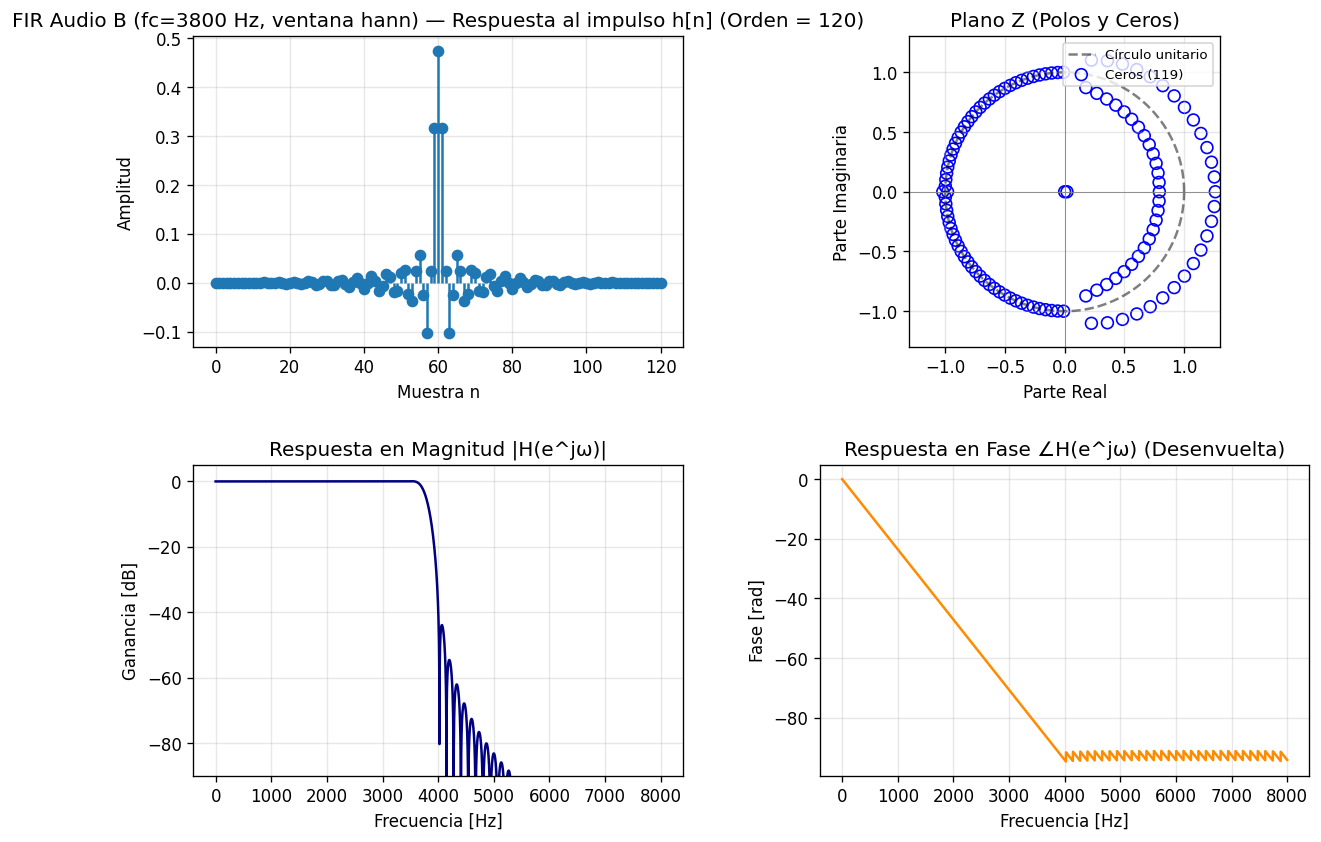

--- Resumen Matemático: FIR Audio B (fc=3800 Hz, ventana hann) ---
Tipo: FIR de fase lineal | Orden M = 120 (121 coeficientes) | Retardo de grupo = 60.0 muestras (3.75 ms)
Primeros 5 coeficientes b[0..4]: [ 0.0e+00  0.0e+00 -1.5e-05 -8.0e-06  5.9e-05]
Ecuación en diferencias: y[n] = Σ_{k=0}^{M} b[k] · x[n - k]
Función de transferencia:  H(z) = Σ_{k=0}^{M} b[k] · z^{-k}


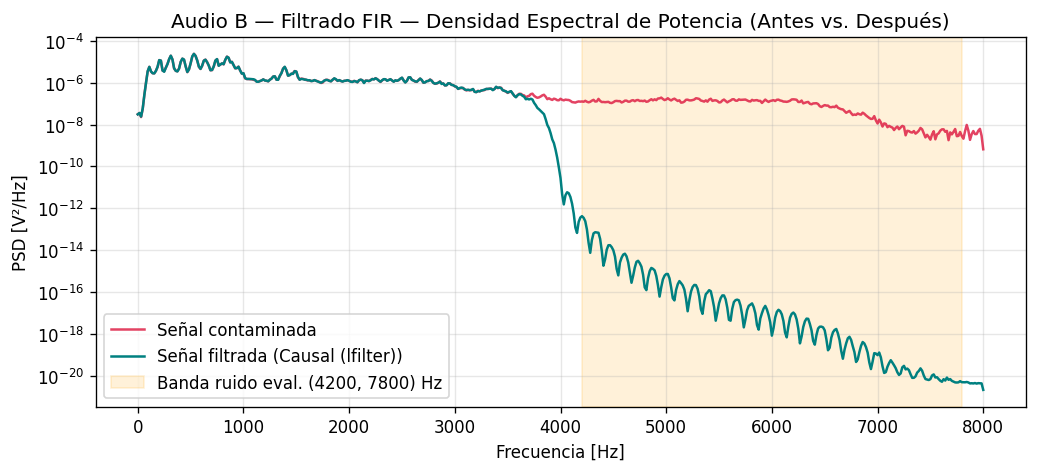

📊 Métricas cuantitativas (Causal (lfilter)):
   • Cambio de potencia en banda de ruido (4200, 7800) Hz: -71.28 dB
   • Cambio de potencia en banda de voz   (300, 3400) Hz:   +0.01 dB
▶️ Audio B filtrado (FIR) (guardado como 'B_FIR.wav'):


In [ ]:

ORDEN_FIR_B = 120
FC_FIR_B = 3800
TIPO_PASO_B = True
VENTANA_FIR_B = "hann"
FASE_CERO_B = False

b_fir_b = signal.firwin(
    numtaps=ORDEN_FIR_B + 1,
    cutoff=FC_FIR_B,
    pass_zero=TIPO_PASO_B,
    window=VENTANA_FIR_B,
    fs=fs_b
)
a_fir_b = np.array([1.0])

inspeccionar_filtro(
    b=b_fir_b,
    a=a_fir_b,
    fs=fs_b,
    titulo=f"FIR Audio B (fc={FC_FIR_B} Hz, ventana {VENTANA_FIR_B})",
    f_zoom_resp=None
)

audio_b_fir, metricas_b_fir = aplicar_y_comparar(
    senal_orig=audio_b,
    b=b_fir_b,
    a=a_fir_b,
    fs=fs_b,
    banda_ruido=(4200, 7800),
    banda_voz=(300, 3400),
    fase_cero=FASE_CERO_B,
    n_fft=1024,
    f_zoom=None,
    titulo="Audio B — Filtrado FIR"
)

guardar_y_reproducir("B_FIR.wav", fs_b, audio_b_fir, etiqueta="Audio B filtrado (FIR)")

## 4. Validación y contraste mediante filtros IIR
Diseño de filtros IIR de biblioteca (`iirnotch` de orden 2 para el Audio A y `butter` pasa-bajas para el Audio B), comparación de polos/ceros en el Plano Z y exportación de `A_IIR.wav` y `B_IIR.wav`.

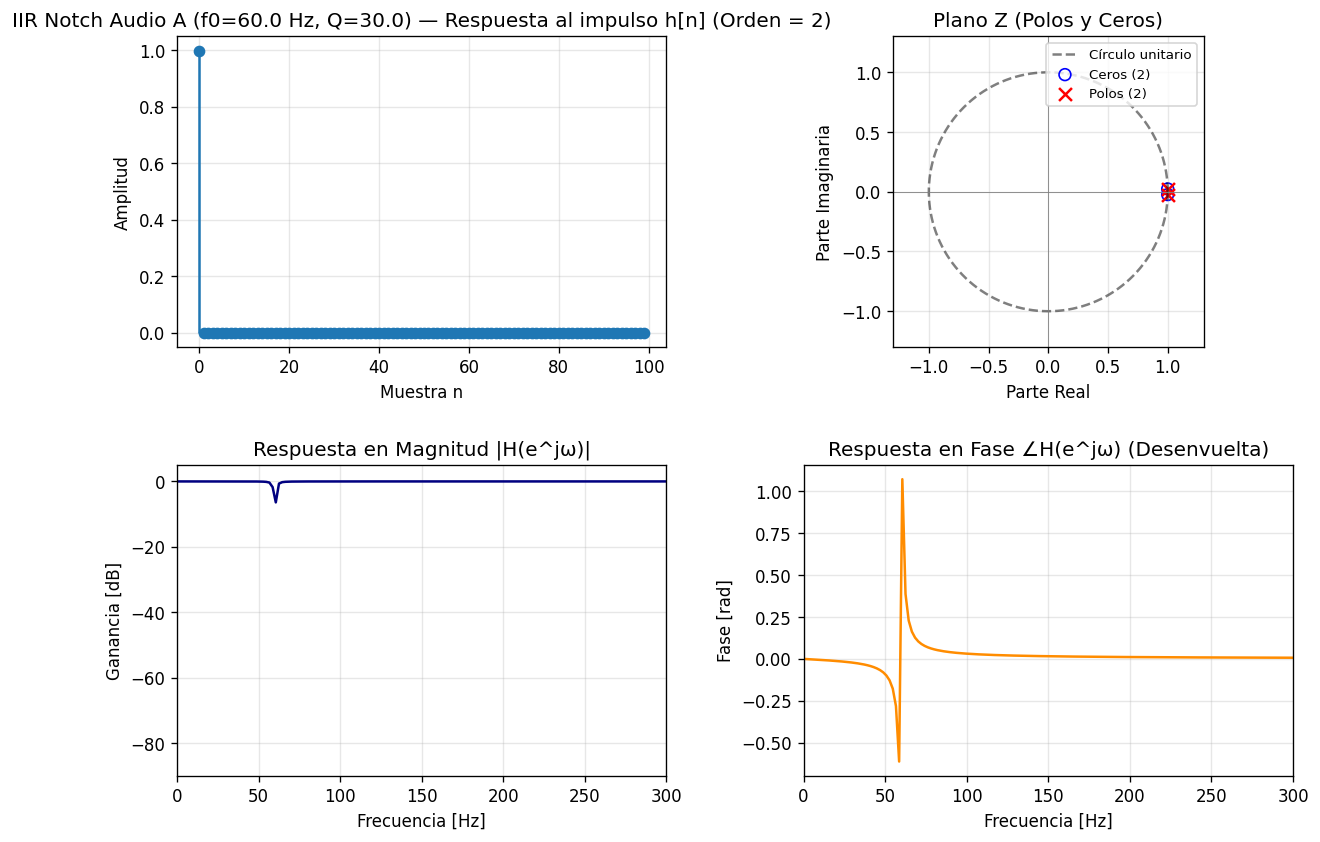

--- Resumen Matemático: IIR Notch Audio A (f0=60.0 Hz, Q=30.0) ---
Tipo: IIR | Orden = 2 | Máximo radio de polos = 0.99961 (< 1 => Estable)
Coeficientes numerador b:   [ 0.999607 -1.99866   0.999607]
Coeficientes denominador a: [ 1.       -1.99866   0.999215]
Ecuación en diferencias: y[n] = Σ b[k]·x[n-k] - Σ_{m=1}^{N} a[m]·y[n-m]


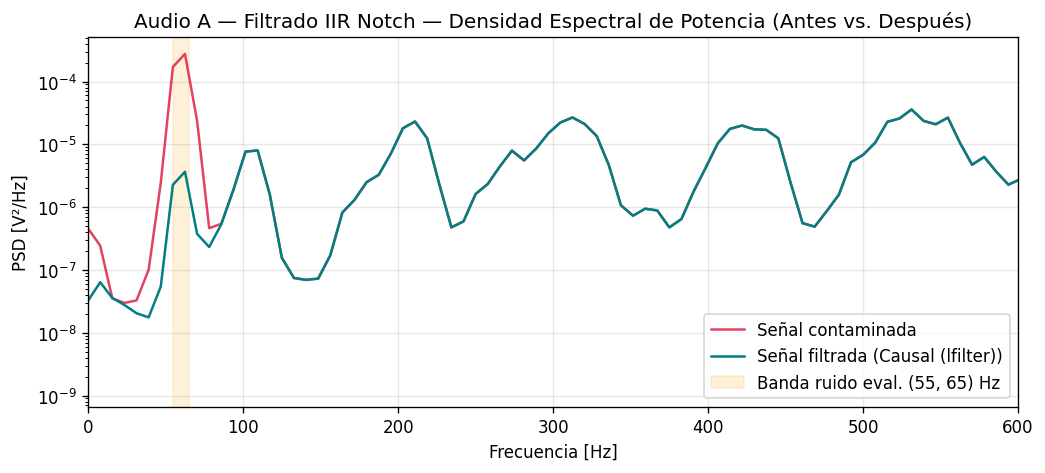

📊 Métricas cuantitativas (Causal (lfilter)):
   • Cambio de potencia en banda de ruido (55, 65) Hz: -18.77 dB
   • Cambio de potencia en banda de voz   (120, 3500) Hz:   -0.00 dB
▶️ Audio A filtrado (IIR) (guardado como 'A_IIR.wav'):


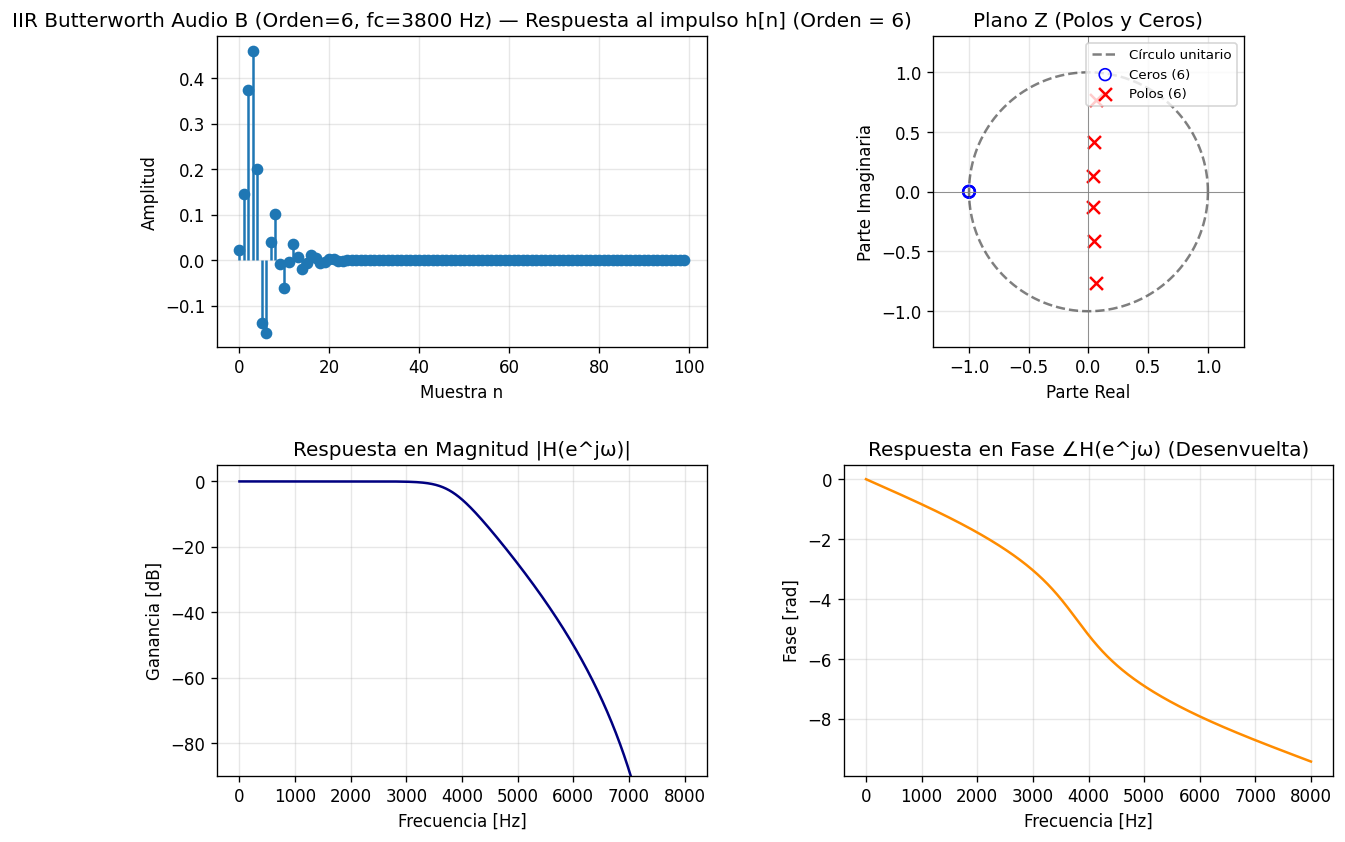

--- Resumen Matemático: IIR Butterworth Audio B (Orden=6, fc=3800 Hz) ---
Tipo: IIR | Orden = 6 | Máximo radio de polos = 0.76798 (< 1 => Estable)
Coeficientes numerador b:   [0.023235 0.139413 0.348532 0.464709 0.348532 0.139413 0.023235]
Coeficientes denominador a: [ 1.       -0.296712  0.810554 -0.141865  0.122758 -0.009592  0.001927]
Ecuación en diferencias: y[n] = Σ b[k]·x[n-k] - Σ_{m=1}^{N} a[m]·y[n-m]


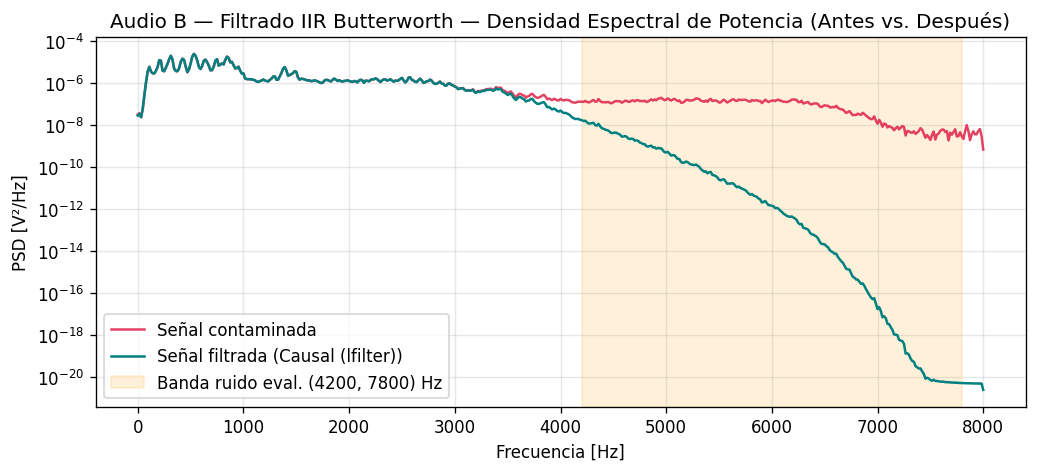

📊 Métricas cuantitativas (Causal (lfilter)):
   • Cambio de potencia en banda de ruido (4200, 7800) Hz: -19.40 dB
   • Cambio de potencia en banda de voz   (300, 3400) Hz:   -0.01 dB
▶️ Audio B filtrado (IIR) (guardado como 'B_IIR.wav'):


In [ ]:


F0_NOTCH = 60.0         # Frecuencia exacta a rechazar (Hz)
Q_NOTCH = 30.0          # Factor de calidad (Q = f0 / ancho_banda -> BW = 2 Hz)
FASE_CERO_IIR_A = False # False = causal (lfilter); True = fase cero (filtfilt)

b_iir_a, a_iir_a = signal.iirnotch(w0=F0_NOTCH, Q=Q_NOTCH, fs=fs_a)

inspeccionar_filtro(
    b=b_iir_a,
    a=a_iir_a,
    fs=fs_a,
    titulo=f"IIR Notch Audio A (f0={F0_NOTCH} Hz, Q={Q_NOTCH})",
    f_zoom_resp=300
)

audio_a_iir, metricas_a_iir = aplicar_y_comparar(
    senal_orig=audio_a,
    b=b_iir_a,
    a=a_iir_a,
    fs=fs_a,
    banda_ruido=(55, 65),
    banda_voz=(120, 3500),
    fase_cero=FASE_CERO_IIR_A,
    n_fft=2048,
    f_zoom=600,
    titulo="Audio A — Filtrado IIR Notch"
)

guardar_y_reproducir("A_IIR.wav", fs_a, audio_a_iir, etiqueta="Audio A filtrado (IIR)")



# DISEÑO IIR — AUDIO B (BUTTERWORTH PASA-BAJAS)
ORDEN_IIR_B = 6
FC_IIR_B = 3800
FASE_CERO_IIR_B = False

b_iir_b, a_iir_b = signal.butter(N=ORDEN_IIR_B, Wn=FC_IIR_B, btype="low", fs=fs_b)

inspeccionar_filtro(
    b=b_iir_b,
    a=a_iir_b,
    fs=fs_b,
    titulo=f"IIR Butterworth Audio B (Orden={ORDEN_IIR_B}, fc={FC_IIR_B} Hz)",
    f_zoom_resp=None
)

audio_b_iir, metricas_b_iir = aplicar_y_comparar(
    senal_orig=audio_b,
    b=b_iir_b,
    a=a_iir_b,
    fs=fs_b,
    banda_ruido=(4200, 7800),
    banda_voz=(300, 3400),
    fase_cero=FASE_CERO_IIR_B,
    n_fft=1024,
    f_zoom=None,
    titulo="Audio B — Filtrado IIR Butterworth"
)

guardar_y_reproducir("B_IIR.wav", fs_b, audio_b_iir, etiqueta="Audio B filtrado (IIR)")

## 5. Resumen cuantitativo comparativo (FIR vs. IIR)
Tabla consolidada de orden del filtro, atenuación en banda de ruido, variación en banda de voz y modo de filtrado (causal vs. fase cero) para los cuatro casos evaluados.

In [ ]:

print(f"{'Caso':<12} | {'Orden':<6} | {'Aten. Ruido [dB]':<18} | {'Var. Voz [dB]':<15} | {'Modo de Filtrado'}")
print("-" * 82)
print(f"{'Audio A FIR':<12} | {len(b_fir_a)-1:<6} | {metricas_a_fir['aten_ruido_db']:+14.2f} dB | {metricas_a_fir['var_voz_db']:+11.2f} dB | {metricas_a_fir['modo']}")
print(f"{'Audio A IIR':<12} | {max(len(b_iir_a),len(a_iir_a))-1:<6} | {metricas_a_iir['aten_ruido_db']:+14.2f} dB | {metricas_a_iir['var_voz_db']:+11.2f} dB | {metricas_a_iir['modo']}")
print(f"{'Audio B FIR':<12} | {len(b_fir_b)-1:<6} | {metricas_b_fir['aten_ruido_db']:+14.2f} dB | {metricas_b_fir['var_voz_db']:+11.2f} dB | {metricas_b_fir['modo']}")
print(f"{'Audio B IIR':<12} | {max(len(b_iir_b),len(a_iir_b))-1:<6} | {metricas_b_iir['aten_ruido_db']:+14.2f} dB | {metricas_b_iir['var_voz_db']:+11.2f} dB | {metricas_b_iir['modo']}")

Caso         | Orden  | Aten. Ruido [dB]   | Var. Voz [dB]   | Modo de Filtrado
----------------------------------------------------------------------------------
Audio A FIR  | 1200   |          -9.56 dB |       -0.01 dB | Causal (lfilter)
Audio A IIR  | 2      |         -18.77 dB |       -0.00 dB | Causal (lfilter)
Audio B FIR  | 120    |         -71.28 dB |       +0.01 dB | Causal (lfilter)
Audio B IIR  | 6      |         -19.40 dB |       -0.01 dB | Causal (lfilter)
